In [1]:
import re
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 노트북이 notebooks/ 안에서 실행되든 프로젝트 루트에서 실행되든 data 폴더를 찾도록
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "music"

# 세미콜론 구분 + 소수점 쉼표, 엑셀 오류 문자열은 결측으로
na = ["#VALUE!", "#value", "#N/A", "NA", ""]
df = pd.read_csv(DATA / "subject-info.csv", sep=";", decimal=",", na_values=na)

print("shape:", df.shape)
print("Exit of the study:", df["Exit of the study"].value_counts(dropna=False).sort_index().to_dict())
print("Cause of death   :", df["Cause of death"].value_counts(dropna=False).sort_index().to_dict())


shape: (992, 103)
Exit of the study: {1.0: 11, 2.0: 20, 3.0: 266, nan: 695}
Cause of death   : {0: 726, 1: 61, 3: 94, 6: 100, 7: 11}


In [2]:
exit_col, cod_col = "Exit of the study", "Cause of death"

# 환자 ID 중복 확인 (환자 단위 분할의 전제)
assert df["Patient ID"].is_unique

# 제외 단계별 인원 기록 (보고서용)
flow = [("원본", len(df), int((df[cod_col] == 3).sum()))]

# 1) 추적탈락(1), 심장이식(2) 제외. 생존자는 Exit가 빈칸(NaN)이라 그대로 남음
base = df.loc[~df[exit_col].isin([1, 2])].copy()
flow.append(("추적탈락·이식 제외", len(base), int((base[cod_col] == 3).sum())))

# 2) 나이 ">89" 제외 후 숫자로 변환
is_89 = base["Age"].astype(str).str.strip() == ">89"
base = base.loc[~is_89].copy()
base["Age"] = pd.to_numeric(base["Age"])
flow.append(("나이 >89 제외", len(base), int((base[cod_col] == 3).sum())))

# 정답: SCD(3)=1, 생존(0)과 다른 원인 사망(1, 6, 7)=0
base["label_scd"] = (base[cod_col] == 3).astype(int)

flow = pd.DataFrame(flow, columns=["단계", "환자 수", "SCD"])
print(flow.to_string(index=False))
print("\n사망 원인별:", base[cod_col].value_counts().sort_index().to_dict())
print(f"SCD 비율: {base['label_scd'].mean():.3f}")


        단계  환자 수  SCD
        원본   992   94
추적탈락·이식 제외   961   94
 나이 >89 제외   960   94

사망 원인별: {0: 694, 1: 61, 3: 94, 6: 100, 7: 11}
SCD 비율: 0.098


In [3]:
SPLIT_SEED = 42

def assign_splits(ids_by_target):
    """팀 레포 _assign_splits와 같은 규칙: 정답별로 sha256 순서로 정렬 후 70/15/나머지"""
    assignments = {}
    for target, ids in ids_by_target.items():
        ids = sorted(
            ids,
            key=lambda pid: (
                hashlib.sha256(f"{SPLIT_SEED}:{target}:{pid}".encode()).hexdigest(),
                pid,
            ),
        )
        n = len(ids)
        train_end, val_size = n * 70 // 100, n * 15 // 100
        for i, pid in enumerate(ids):
            if i < train_end:
                assignments[pid] = "train"
            elif i < train_end + val_size:
                assignments[pid] = "validation"
            else:
                assignments[pid] = "test"
    return assignments

ids_by_target = {t: base.loc[base["label_scd"] == t, "Patient ID"].tolist() for t in (0, 1)}
base["split"] = base["Patient ID"].map(assign_splits(ids_by_target))

assert base["split"].notna().all()
print(pd.crosstab(base["split"], base["label_scd"], margins=True)
        .reindex(["train", "validation", "test", "All"]))
print("\n세트별 SCD 비율:", base.groupby("split")["label_scd"].mean().round(3).to_dict())


label_scd     0   1  All
split                   
train       606  65  671
validation  129  14  143
test        131  15  146
All         866  94  960

세트별 SCD 비율: {'test': 0.103, 'train': 0.097, 'validation': 0.098}


In [4]:
RAW = list(df.columns)            # 원본 103개 컬럼 이름 (열 번호 = 위치 + 1)

def at(positions):
    """열 번호(1부터) → 원본 컬럼 이름"""
    return [RAW[p - 1] for p in positions]

# 열 번호로 그룹 정의 (팀 music.py와 같은 번호 체계)
TEAM_CLIN_POS = [p for p in range(6, 59) if p not in (25, 30)] + list(range(91, 104))  # 팀 64개
CLIN_POS = list(range(6, 59)) + list(range(91, 104))                                    # 우리 66개
ECG_POS  = list(range(60, 70)) + [p for p in range(72, 91) if p not in (81, 85)]        # 20분 ECG 10 + 홀터 17
CAT_POS  = [11, 14, 20, 21, 22, 53, 54, 60, 69, 72, 84]   # 범주형 11개 (팀 기준 NYHA·실신·승모판 역류 추가)
NA999_POS = [62, 83]                          # PR 간격, 24h 상심실 조기박동: 999 = 측정 불가

assert len(TEAM_CLIN_POS) == 64 and len(CLIN_POS) == 66 and len(ECG_POS) == 27
assert not set(CLIN_POS) & set(ECG_POS)
print("팀 64개에 추가한 임상 변수:", at(sorted(set(CLIN_POS) - set(TEAM_CLIN_POS))))
print("103개 중 입력에서 뺀 10개:", at(sorted(set(range(1, 104)) - set(CLIN_POS) - set(ECG_POS))))

# 컬럼 이름 정리: 이중/끝 공백 제거, 이름이 같은 Average RR 두 개는 열 번호로 구분
def clean(p):
    if p == 67: return "Average RR (ms) [ECG]"
    if p == 74: return "Average RR (ms) [Holter]"
    return re.sub(r"\s+", " ", RAW[p - 1]).strip()

NAME = {p: clean(p) for p in CLIN_POS + ECG_POS}
assert len(set(NAME.values())) == 93
CLIN = [NAME[p] for p in CLIN_POS]
ECG  = [NAME[p] for p in ECG_POS]
CATS = [NAME[p] for p in CAT_POS]

def make_x(base):
    X = base[at(CLIN_POS + ECG_POS)].copy()
    X.columns = [NAME[p] for p in CLIN_POS + ECG_POS]

    # 999 → 결측 (대부분 심방세동 환자라 측정 불가)
    for p in NA999_POS:
        X[NAME[p]] = pd.to_numeric(X[NAME[p]], errors="coerce").replace(999, np.nan)

    # 범주형 코드 → 문자 "c숫자". PSVT의 9는 코드표 정의대로 c9 범주로 유지
    for c in CATS:
        s = pd.to_numeric(X[c], errors="coerce")
        X[c] = s.map(lambda v: f"c{int(v)}" if pd.notna(v) else np.nan)

    # 숫자도 범주도 아닌 컬럼이 남으면 멈춤
    left = [c for c in X.columns if c not in CATS and not pd.api.types.is_numeric_dtype(X[c])]
    assert not left, left
    return X

X = make_x(base)
y = base["label_scd"]
print("\nX:", X.shape, "| 임상", len(CLIN), "| ECG", len(ECG), "| 범주형", len(CATS))
print("범주형:", CATS)
print("PSVT:", X[NAME[84]].value_counts(dropna=False).to_dict())


팀 64개에 추가한 임상 변수: ['cigarettes /year', 'Normalized Troponin']
103개 중 입력에서 뺀 10개: ['Patient ID', 'Follow-up period from enrollment (days)', 'days_4years', 'Exit of the study', 'Cause of death', 'Hig-resolution ECG available', 'Holter available', 'Holter onset (hh:mm:ss)', 'Number of ventricular premature contractions per hour', 'Longest RR pause (ms)']

X: (960, 93) | 임상 66 | ECG 27 | 범주형 11
범주형: ['NYHA class', 'HF etiology - Diagnosis', 'Prior implantable device', 'Prior Revascularization', 'Syncope', 'Mitral valve insufficiency', 'Mitral flow pattern', 'ECG rhythm', 'Intraventricular conduction disorder', 'Holter rhythm', 'Paroxysmal supraventricular tachyarrhythmia']
PSVT: {'c0': 444, 'c9': 256, 'c1': 191, nan: 64, 'c2': 4, 'c3': 1}


In [5]:
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, roc_curve)

METRICS = ["AUROC", "AP", "민감도", "특이도", "Brier"]

def youden_threshold(y, p):
    """민감도 + 특이도가 가장 큰 임계값 (학습 데이터의 교차검증 예측으로 정함)"""
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])

def point_metrics(y, p, thr):
    y, p = np.asarray(y), np.asarray(p)
    tn, fp, fn, tp = confusion_matrix(y, (p >= thr).astype(int), labels=[0, 1]).ravel()
    return {
        "AUROC": roc_auc_score(y, p),
        "AP": average_precision_score(y, p),
        "민감도": tp / (tp + fn),
        "특이도": tn / (tn + fp),
        "Brier": brier_score_loss(y, p),
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
    }

def bootstrap_ci(y, p, thr, n_boot=2000, seed=42):
    """층화 bootstrap: SCD와 비SCD를 각각 같은 인원수로 복원추출해 2,000번 다시 채점"""
    y, p = np.asarray(y), np.asarray(p)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    rng = np.random.default_rng(seed)
    boots = {k: [] for k in METRICS}
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        m = point_metrics(y[idx], p[idx], thr)
        for k in METRICS:
            boots[k].append(m[k])
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in boots.items()}

def evaluate(y, p, thr, name):
    m, ci = point_metrics(y, p, thr), bootstrap_ci(y, p, thr)
    row = {"모델": name, "임계값": round(thr, 3)}
    for k in METRICS:
        row[k] = round(m[k], 3)
        row[f"{k} 95%CI"] = f"{ci[k][0]:.3f}–{ci[k][1]:.3f}"
    row.update({k: int(m[k]) for k in ["TP", "FN", "FP", "TN"]})
    return row

# 점검: 모든 검증 환자에게 학습 SCD 비율을 똑같이 주는 '아무것도 안 배운' 기준
is_tr, is_va = base["split"].eq("train"), base["split"].eq("validation")
prior = y[is_tr].mean()
dummy = evaluate(y[is_va], np.full(is_va.sum(), prior), 0.5, "Dummy prior")
print(pd.DataFrame([dummy]).T.to_string())


                       0
모델           Dummy prior
임계값                  0.5
AUROC                0.5
AUROC 95%CI  0.500–0.500
AP                 0.098
AP 95%CI     0.098–0.098
민감도                  0.0
민감도 95%CI    0.000–0.000
특이도                  1.0
특이도 95%CI    1.000–1.000
Brier              0.088
Brier 95%CI  0.088–0.088
TP                     0
FN                    14
FP                     0
TN                   129


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_logit(cols, team=False):
    cat = [c for c in cols if c in CATS]
    num = [c for c in cols if c not in CATS]
    if team:   # 팀 01_music_practice와 같은 설정
        num_imp = SimpleImputer(strategy="median")
        cat_imp = SimpleImputer(strategy="most_frequent")
        clf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000, random_state=SEED)
    else:      # 우리 기준: 결측 표시 추가, 범주 결측은 'missing' 범주, C는 학습 CV로 선택
        num_imp = SimpleImputer(strategy="median", add_indicator=True)
        cat_imp = SimpleImputer(strategy="constant", fill_value="missing")
        clf = LogisticRegressionCV(Cs=10, cv=cv5, scoring="average_precision",
                                   class_weight="balanced", max_iter=5000)
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", num_imp), ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", cat_imp),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
    ])
    return Pipeline([("pre", pre), ("clf", clf)])

X_tr, y_tr = X[is_tr], y[is_tr]
X_va, y_va = X[is_va], y[is_va]

# 점검: 팀 베이스라인 재현 (팀 임상 64개 + 팀 설정)
CLIN64 = [NAME[p] for p in TEAM_CLIN_POS]
team_model = make_logit(CLIN64, team=True).fit(X_tr[CLIN64], y_tr)
p_team = team_model.predict_proba(X_va[CLIN64])[:, 1]
print(f"팀 방식 재현 : AUROC {roc_auc_score(y_va, p_team):.3f} | AP {average_precision_score(y_va, p_team):.3f}  (검증 {len(y_va)}명)")
print("팀 git 결과  : AUROC 0.685 | AP 0.184  (검증 144명)")


팀 방식 재현 : AUROC 0.686 | AP 0.185  (검증 143명)
팀 git 결과  : AUROC 0.685 | AP 0.184  (검증 144명)


In [7]:
FEATURE_SETS = {"임상": CLIN, "ECG": ECG, "결합": CLIN + ECG}
runs = {"Logit-팀재현(임상64)": (CLIN64, True)}
runs.update({f"Logit-{k}": (cols, False) for k, cols in FEATURE_SETS.items()})

logit_rows, cv_rows, logit_pred = [dummy], [], {}
for name, (cols, team) in runs.items():
    # 1) 학습 671명 안에서 5겹 교차검증 예측 → 학습 CV 점수와 임계값
    p_cv = cross_val_predict(make_logit(cols, team), X_tr[cols], y_tr, cv=cv5, method="predict_proba")[:, 1]
    thr = youden_threshold(y_tr, p_cv)
    # 2) 학습 671명 전체로 다시 학습 → 검증 143명 채점
    model = make_logit(cols, team).fit(X_tr[cols], y_tr)
    p_va = model.predict_proba(X_va[cols])[:, 1]
    logit_pred[name] = p_va
    C = model[-1].C_[0] if hasattr(model[-1], "C_") else model[-1].C
    cv_rows.append({"모델": name, "입력 수": len(cols), "C": round(C, 4),
                    "학습CV AUROC": round(roc_auc_score(y_tr, p_cv), 3),
                    "학습CV AP": round(average_precision_score(y_tr, p_cv), 3)})
    logit_rows.append(evaluate(y_va, p_va, thr, name))

print("[학습 데이터 5겹 CV]")
print(pd.DataFrame(cv_rows).set_index("모델").to_string())
logit_table = pd.DataFrame(logit_rows).set_index("모델")
print("\n[검증 세트 143명, SCD 14명]")
print(logit_table[["AUROC", "AUROC 95%CI", "AP", "AP 95%CI", "Brier"]].to_string())
print()
print(logit_table[["임계값", "민감도", "특이도", "TP", "FN", "FP", "TN"]].to_string())


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
/home/mingyu/poc-test/.venv

[학습 데이터 5겹 CV]
                 입력 수       C  학습CV AUROC  학습CV AP
모델                                                
Logit-팀재현(임상64)    64  1.0000       0.585    0.132
Logit-임상           66  0.0060       0.605    0.155
Logit-ECG          27  0.0464       0.640    0.154
Logit-결합           93  0.0060       0.703    0.189

[검증 세트 143명, SCD 14명]
                 AUROC  AUROC 95%CI     AP     AP 95%CI  Brier
모델                                                            
Dummy prior      0.500  0.500–0.500  0.098  0.098–0.098  0.088
Logit-팀재현(임상64)  0.686  0.531–0.824  0.185  0.128–0.358  0.196
Logit-임상         0.646  0.498–0.784  0.176  0.115–0.366  0.205
Logit-ECG        0.626  0.457–0.784  0.253  0.115–0.474  0.205
Logit-결합         0.620  0.451–0.781  0.221  0.114–0.464  0.192

                   임계값    민감도    특이도  TP  FN  FP   TN
모델                                                   
Dummy prior      0.500  0.000  1.000   0  14   0  129
Logit-팀재현(임상64)  0.197  0.857  0.473  12   2  68   6

In [9]:
import time
import warnings
import h2o
from h2o.automl import H2OAutoML

warnings.filterwarnings("ignore", message="Converting H2O frame")
h2o.connect(ip="127.0.0.1", port=54321, verbose=False)
h2o.no_progress()

# 로지스틱 회귀(cv5)와 똑같은 5개 조를 H2O에도 쓰기 위한 조 번호 (0~4)
fold_tr = np.zeros(len(X_tr), dtype=int)
for k, (_, idx) in enumerate(cv5.split(X_tr, y_tr)):
    fold_tr[idx] = k

def to_h2o(Xpart, ypart, cols, fold=None):
    """pandas 표 → H2O 표. 범주형과 정답은 enum(범주)으로 지정"""
    d = Xpart[cols].copy()
    d["label_scd"] = ypart.astype(str).values
    if fold is not None:
        d["fold"] = fold
    types = {c: "enum" for c in cols if c in CATS}
    types["label_scd"] = "enum"
    return h2o.H2OFrame(d, column_types=types)

TOP_K = 5

def run_automl(cols, tag):
    tr = to_h2o(X_tr, y_tr, cols, fold_tr)
    va = to_h2o(X_va, y_va, cols)
    aml = H2OAutoML(max_models=20, max_runtime_secs=900, sort_metric="AUCPR",
                    include_algos=["GBM", "DRF", "XGBoost"], seed=SEED,
                    keep_cross_validation_predictions=True,
                    project_name=f"p03_{tag}_{int(time.time())}")
    aml.train(x=cols, y="label_scd", training_frame=tr, fold_column="fold")

    # 리더보드 상위 TOP_K개 모델의 모의고사 예측과 검증 예측을 모음
    ids = aml.leaderboard.as_data_frame()["model_id"].tolist()[:TOP_K]
    p_cv, p_va = [], []
    for mid in ids:
        m = h2o.get_model(mid)
        p_cv.append(m.cross_validation_holdout_predictions()["p1"].as_data_frame()["p1"].values)
        p_va.append(m.predict(va)["p1"].as_data_frame()["p1"].values)
    return aml, ids, np.array(p_cv), np.array(p_va)   # 모양: (TOP_K, 환자 수)

def short(model_id):
    """GBM_1_AutoML_3_20261020_01910 → GBM_1 / XGBoost_grid_1_AutoML_..._model_3 → XGBoost_grid_1_model_3"""
    return re.sub(r"_AutoML_[\d_]+?(?=_model|$)", "", model_id)

TAGS = {"임상": "clin", "ECG": "ecg", "결합": "comb"}
aml_rows, aml_cv_rows, aml_pred, aml_runs = [], [], {}, {}
for k, cols in FEATURE_SETS.items():
    t0 = time.time()
    aml, ids, P_cv, P_va = run_automl(cols, TAGS[k])
    aml_runs[k] = aml
    for label, p_cv, p_va in [("1등", P_cv[0], P_va[0]),
                              (f"상위{TOP_K}평균", P_cv.mean(axis=0), P_va.mean(axis=0))]:
        name = f"AutoML-{k}({label})"
        thr = youden_threshold(y_tr, p_cv)
        aml_pred[name] = p_va
        aml_cv_rows.append({"모델": name, "입력 수": len(cols),
                            "학습CV AUROC": round(roc_auc_score(y_tr, p_cv), 3),
                            "학습CV AP": round(average_precision_score(y_tr, p_cv), 3)})
        aml_rows.append(evaluate(y_va, p_va, thr, name))
    print(f"{k}: 상위 {TOP_K}개 = {[short(i) for i in ids]} | {time.time() - t0:.0f}초")

print("\n[학습 데이터 5겹 CV]")
print(pd.DataFrame(aml_cv_rows).set_index("모델").to_string())
aml_table = pd.DataFrame(aml_rows).set_index("모델")
print("\n[검증 세트 143명, SCD 14명]")
print(aml_table[["AUROC", "AUROC 95%CI", "AP", "AP 95%CI", "Brier"]].to_string())
print()
print(aml_table[["임계값", "민감도", "특이도", "TP", "FN", "FP", "TN"]].to_string())



00:28:55.207: Fold column fold will be used for cross-validation. nfolds parameter will be ignored.

임상: 상위 5개 = ['XGBoost_1', 'GBM_3', 'XGBoost_grid_1_model_4', 'GBM_grid_1_model_3', 'XGBoost_grid_1_model_5'] | 29초

00:29:24.242: Fold column fold will be used for cross-validation. nfolds parameter will be ignored.

ECG: 상위 5개 = ['GBM_1', 'XGBoost_1', 'XGBoost_grid_1_model_4', 'XGBoost_grid_1_model_3', 'GBM_grid_1_model_1'] | 28초

00:29:52.190: Fold column fold will be used for cross-validation. nfolds parameter will be ignored.

결합: 상위 5개 = ['GBM_3', 'GBM_grid_1_model_2', 'XGBoost_grid_1_model_4', 'GBM_4', 'XGBoost_1'] | 32초

[학습 데이터 5겹 CV]
                   입력 수  학습CV AUROC  학습CV AP
모델                                          
AutoML-임상(1등)        66       0.670    0.191
AutoML-임상(상위5평균)     66       0.687    0.168
AutoML-ECG(1등)       27       0.674    0.171
AutoML-ECG(상위5평균)    27       0.651    0.171
AutoML-결합(1등)        93       0.690    0.181
AutoML-결합(상위5평균)     93       0.69

In [12]:
lb_rows = []
for k, aml in aml_runs.items():
    lb = aml.leaderboard.as_data_frame()
    algo = lb["model_id"].str.split("_").str[0]
    for a in ["GBM", "XGBoost", "DRF", "XRT"]:
        s = lb[algo == a]
        lb_rows.append({"입력": k, "알고리즘": a, "모델 수": len(s),
                        "CV AUC 최저": s["auc"].min(), "CV AUC 최고": s["auc"].max(),
                        "상위5 포함": int(s.index.isin(range(TOP_K)).sum())})
lb_summary = pd.DataFrame(lb_rows).set_index(["입력", "알고리즘"]).round(3)
print(lb_summary.to_string())


             모델 수  CV AUC 최저  CV AUC 최고  상위5 포함
입력  알고리즘                                       
임상  GBM         9      0.567      0.646       2
    XGBoost     9      0.599      0.681       3
    DRF         1      0.573      0.573       0
    XRT         1      0.624      0.624       0
ECG GBM         9      0.540      0.674       2
    XGBoost     9      0.567      0.651       3
    DRF         1      0.619      0.619       0
    XRT         1      0.601      0.601       0
결합  GBM         9      0.579      0.690       3
    XGBoost     9      0.636      0.681       2
    DRF         1      0.622      0.622       0
    XRT         1      0.623      0.623       0


                   학습CV AUROC  학습CV AP  검증 AUROC  검증 AP  검증 Brier  검증 민감도  검증 특이도
모델                                                                               
Dummy prior               NaN      NaN     0.500  0.098     0.088   0.000   1.000
Logit-팀재현(임상64)         0.585    0.132     0.686  0.185     0.196   0.857   0.473
Logit-임상                0.605    0.155     0.646  0.176     0.205   0.571   0.690
Logit-ECG               0.640    0.154     0.626  0.253     0.205   0.643   0.643
Logit-결합                0.703    0.189     0.620  0.221     0.192   0.357   0.798
AutoML-임상(상위5평균)        0.687    0.168     0.657  0.159     0.090   0.786   0.558
AutoML-ECG(상위5평균)       0.651    0.171     0.581  0.171     0.088   0.429   0.690
AutoML-결합(상위5평균)        0.698    0.185     0.618  0.132     0.092   0.714   0.558


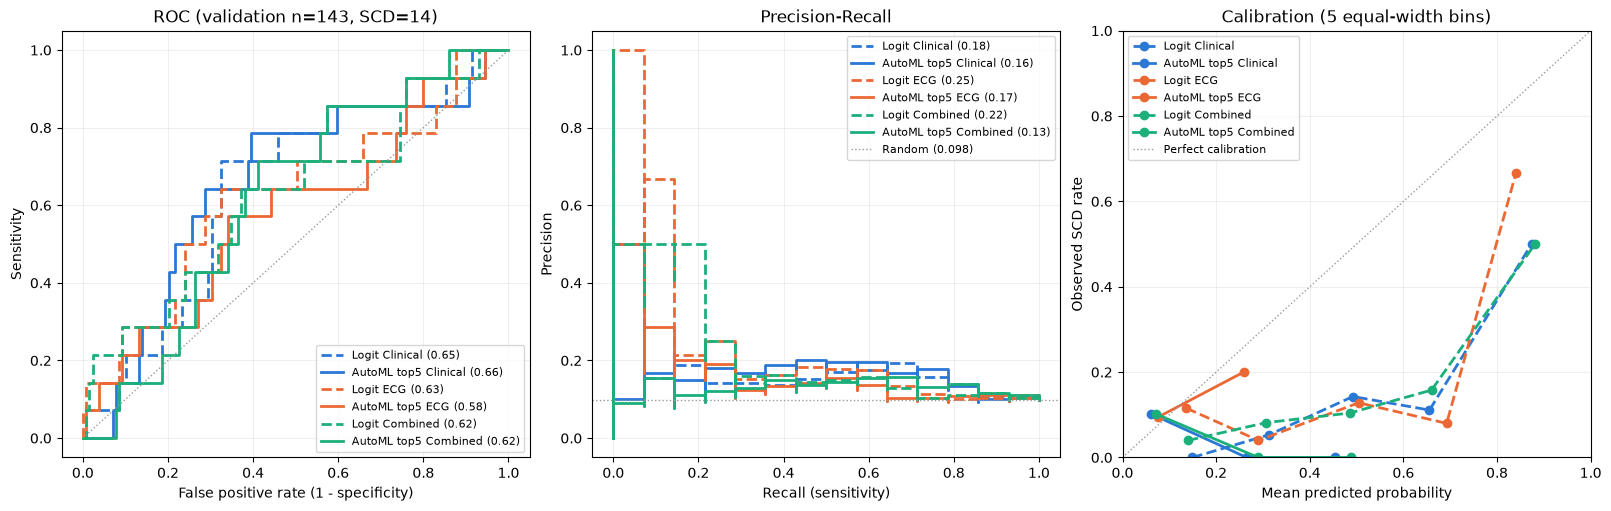

In [13]:
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

OUT = ROOT / "results" / "03"
OUT.mkdir(parents=True, exist_ok=True)

# 1) 전체 비교표: 로지스틱(셀 7) + AutoML 상위5 평균(셀 8). 1등 결과는 aml_table에 보관
all_table = pd.concat([logit_table, aml_table[~aml_table.index.str.contains("1등")]])
cv_all = pd.concat([pd.DataFrame(cv_rows), pd.DataFrame(aml_cv_rows)]).set_index("모델")
summary = (all_table[["AUROC", "AP", "Brier", "민감도", "특이도"]]
           .add_prefix("검증 ")
           .join(cv_all[["학습CV AUROC", "학습CV AP"]]))
summary = summary[["학습CV AUROC", "학습CV AP", "검증 AUROC", "검증 AP", "검증 Brier", "검증 민감도", "검증 특이도"]]
print(summary.to_string())
all_table.to_csv(OUT / "03_validation_metrics.csv", encoding="utf-8-sig")
summary.to_csv(OUT / "03_summary.csv", encoding="utf-8-sig")

# 2) 그림: 색 = 입력 세트, 선 모양 = 모델 (점선 로지스틱 / 실선 AutoML 상위5 평균)
SETS = {"임상": ("Clinical", "#2a78d6"), "ECG": ("ECG", "#eb6834"), "결합": ("Combined", "#1baf7a")}
curves = []
for k, (en, color) in SETS.items():
    curves.append((f"Logit {en}", logit_pred[f"Logit-{k}"], color, "--"))
    curves.append((f"AutoML top{TOP_K} {en}", aml_pred[f"AutoML-{k}(상위{TOP_K}평균)"], color, "-"))

prev = y_va.mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 5), layout="constrained")
for label, p, color, ls in curves:
    fpr, tpr, _ = roc_curve(y_va, p)
    axes[0].plot(fpr, tpr, color=color, ls=ls, lw=2, label=f"{label} ({roc_auc_score(y_va, p):.2f})")
    prec, rec, _ = precision_recall_curve(y_va, p)
    axes[1].step(rec, prec, where="post", color=color, ls=ls, lw=2,
                 label=f"{label} ({average_precision_score(y_va, p):.2f})")
    frac_pos, mean_pred = calibration_curve(y_va, p, n_bins=5, strategy="uniform")
    axes[2].plot(mean_pred, frac_pos, color=color, ls=ls, lw=2, marker="o", ms=6, label=label)

axes[0].plot([0, 1], [0, 1], color="#999999", lw=1, ls=":")
axes[1].axhline(prev, color="#999999", lw=1, ls=":", label=f"Random ({prev:.3f})")
axes[2].plot([0, 1], [0, 1], color="#999999", lw=1, ls=":", label="Perfect calibration")
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="Sensitivity",
            title=f"ROC (validation n={len(y_va)}, SCD={int(y_va.sum())})")
axes[1].set(xlabel="Recall (sensitivity)", ylabel="Precision", title="Precision-Recall")
axes[2].set(xlabel="Mean predicted probability", ylabel="Observed SCD rate",
            title="Calibration (5 equal-width bins)", xlim=(0, 1), ylim=(0, 1))
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.savefig(OUT / "03_roc_pr_calibration.png", dpi=150, bbox_inches="tight")
plt.show()


In [14]:
bins = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
rows = {}
for label, p, _, _ in curves:
    cut = pd.cut(p, bins=bins, include_lowest=True)
    g = pd.DataFrame({"구간": cut, "SCD": y_va.values}).groupby("구간", observed=False)["SCD"]
    rows[label] = g.count().astype(str) + "명 (SCD " + g.sum().astype(str) + ")"
print(pd.DataFrame(rows).T.to_string())


구간                    (-0.001, 0.2]   (0.2, 0.4]   (0.4, 0.6]   (0.6, 0.8]  (0.8, 1.0]
Logit Clinical          11명 (SCD 0)  56명 (SCD 3)  56명 (SCD 8)  18명 (SCD 2)  2명 (SCD 1)
AutoML top5 Clinical  137명 (SCD 14)   5명 (SCD 0)   1명 (SCD 0)   0명 (SCD 0)  0명 (SCD 0)
Logit ECG               26명 (SCD 3)  50명 (SCD 2)  39명 (SCD 5)  25명 (SCD 2)  3명 (SCD 2)
AutoML top5 ECG       138명 (SCD 13)   5명 (SCD 1)   0명 (SCD 0)   0명 (SCD 0)  0명 (SCD 0)
Logit Combined          25명 (SCD 1)  49명 (SCD 4)  48명 (SCD 5)  19명 (SCD 3)  2명 (SCD 1)
AutoML top5 Combined  137명 (SCD 14)   5명 (SCD 0)   1명 (SCD 0)   0명 (SCD 0)  0명 (SCD 0)


In [16]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
has_holter = base["Holter available"].eq(1)
hol_tr, hol_va = is_tr & has_holter, is_va & has_holter
print(f"홀터 있는 환자: 학습 {hol_tr.sum()}명 (SCD {y[hol_tr].sum()}) | 검증 {hol_va.sum()}명 (SCD {y[hol_va].sum()})")

hol_rows, hol_cv_rows = [], []
for k, cols in FEATURE_SETS.items():
    Xt, yt = X.loc[hol_tr, cols], y[hol_tr]
    Xv, yv = X.loc[hol_va, cols], y[hol_va]
    p_cv = cross_val_predict(make_logit(cols), Xt, yt, cv=cv5, method="predict_proba")[:, 1]
    thr = youden_threshold(yt, p_cv)
    p_va = make_logit(cols).fit(Xt, yt).predict_proba(Xv)[:, 1]
    hol_cv_rows.append({"입력": k,
                        "학습CV AUROC (홀터 905)": round(roc_auc_score(yt, p_cv), 3),
                        "학습CV AP (홀터 905)": round(average_precision_score(yt, p_cv), 3)})
    hol_rows.append(evaluate(yv, p_va, thr, f"Logit-{k}(홀터)"))

# 전체 960명(셀 7) 결과와 나란히 비교
full_cv = (pd.DataFrame(cv_rows).set_index("모델")
           .loc[[f"Logit-{k}" for k in FEATURE_SETS], ["학습CV AUROC", "학습CV AP"]])
full_cv.index = list(FEATURE_SETS)
full_cv.columns = ["학습CV AUROC (전체 960)", "학습CV AP (전체 960)"]
print("\n[학습 CV: 전체 960명 vs 홀터 있는 905명]")
print(full_cv.join(pd.DataFrame(hol_cv_rows).set_index("입력")).to_string())

hol_table = pd.DataFrame(hol_rows).set_index("모델")
print(f"\n[검증 세트, 홀터 있는 {hol_va.sum()}명]")
print(hol_table[["AUROC", "AUROC 95%CI", "AP", "AP 95%CI", "Brier"]].to_string())
hol_table.to_csv(OUT / "03_holter_subgroup_metrics.csv", encoding="utf-8-sig")


홀터 있는 환자: 학습 628명 (SCD 59) | 검증 138명 (SCD 14)

[학습 CV: 전체 960명 vs 홀터 있는 905명]
     학습CV AUROC (전체 960)  학습CV AP (전체 960)  학습CV AUROC (홀터 905)  학습CV AP (홀터 905)
임상                 0.605             0.155                0.573             0.143
ECG                0.640             0.154                0.660             0.172
결합                 0.703             0.189                0.593             0.142

[검증 세트, 홀터 있는 138명]
               AUROC  AUROC 95%CI     AP     AP 95%CI  Brier
모델                                                          
Logit-임상(홀터)   0.632  0.467–0.782  0.181  0.111–0.371  0.203
Logit-ECG(홀터)  0.584  0.415–0.753  0.182  0.104–0.404  0.246
Logit-결합(홀터)   0.626  0.469–0.776  0.202  0.114–0.434  0.217


In [17]:
SEEDS = range(10)   # 5조 나누기를 seed 0~9로 10번 반복 (분할 SPLIT_SEED=42는 그대로)
cohorts = {"전체 960": is_tr, "홀터 905": hol_tr}

rep = []
for cname, mask in cohorts.items():
    yt = y[mask]
    for seed in SEEDS:
        cv_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        for k, cols in FEATURE_SETS.items():
            p = cross_val_predict(make_logit(cols), X.loc[mask, cols], yt,
                                  cv=cv_r, method="predict_proba")[:, 1]
            rep.append({"대상": cname, "seed": seed, "입력": k,
                        "AUROC": roc_auc_score(yt, p), "AP": average_precision_score(yt, p)})
    print(f"{cname} 완료")
rep = pd.DataFrame(rep)
rep.to_csv(OUT / "03_repeated_cv_logit.csv", index=False, encoding="utf-8-sig")

# 1) 입력별 점수: 10번의 평균, 표준편차, 최저, 최고
print("\n[입력별 학습 CV 점수, 10번 반복]")
print(rep.groupby(["대상", "입력"])[["AUROC", "AP"]].agg(["mean", "std", "min", "max"]).round(3).to_string())

# 2) 같은 seed끼리 짝지어 본 차이: ECG를 더하면(결합) 또는 ECG만 쓰면 임상보다 나은가
wide = rep.pivot_table(index=["대상", "seed"], columns="입력", values="AUROC")
diff = pd.DataFrame({"결합−임상": wide["결합"] - wide["임상"],
                     "ECG−임상": wide["ECG"] - wide["임상"]})
for col in diff:
    g = diff.groupby(level="대상")[col]
    print(f"\n[AUROC 차이: {col}]")
    print(pd.DataFrame({"평균": g.mean(), "최저": g.min(), "최고": g.max(),
                        "양수 횟수(10번 중)": g.apply(lambda s: int((s > 0).sum()))}).round(3).to_string())


전체 960 완료
홀터 905 완료

[입력별 학습 CV 점수, 10번 반복]
            AUROC                          AP                     
             mean    std    min    max   mean    std    min    max
대상     입력                                                         
전체 960 ECG  0.634  0.018  0.607  0.665  0.153  0.013  0.139  0.177
       결합   0.648  0.019  0.627  0.684  0.172  0.015  0.153  0.195
       임상   0.630  0.014  0.608  0.654  0.160  0.016  0.133  0.180
홀터 905 ECG  0.650  0.020  0.615  0.688  0.159  0.012  0.144  0.186
       결합   0.639  0.030  0.592  0.674  0.158  0.017  0.126  0.180
       임상   0.587  0.018  0.559  0.613  0.129  0.009  0.115  0.145

[AUROC 차이: 결합−임상]
           평균     최저     최고  양수 횟수(10번 중)
대상                                       
전체 960  0.018 -0.018  0.058             8
홀터 905  0.052  0.003  0.081            10

[AUROC 차이: ECG−임상]
           평균     최저     최고  양수 횟수(10번 중)
대상                                       
전체 960  0.004 -0.032  0.045             7
홀터 905  0.063  0.030

In [18]:
# 환자마다 '자기를 안 본 모델' 점수를 10번 구해 평균 (셀 11과 같은 seed 0~9)
def oof_mean(cols, mask):
    ps = []
    for seed in SEEDS:
        cv_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        ps.append(cross_val_predict(make_logit(cols), X.loc[mask, cols], y[mask],
                                    cv=cv_r, method="predict_proba")[:, 1])
    return np.mean(ps, axis=0)

score = oof_mean(CLIN + ECG, is_tr)
thr = youden_threshold(y_tr, score)
pred = score >= thr
group = np.select([(y_tr == 1) & pred, (y_tr == 1) & ~pred, (y_tr == 0) & pred],
                  ["맞힘(TP)", "놓침(FN)", "헛경보(FP)"], "맞게안심(TN)")
ORDER = ["맞힘(TP)", "놓침(FN)", "헛경보(FP)", "맞게안심(TN)"]
print(f"결합 모델 (10번 평균 점수) | AUROC {roc_auc_score(y_tr, score):.3f} | AP {average_precision_score(y_tr, score):.3f} | 임계값 {thr:.3f}")
print("그룹 인원:", pd.Series(group).value_counts().reindex(ORDER).to_dict())

# 비교할 변수: 02의 중요 변수 + 기본 임상 지표 + 결측 관련
tr = base.loc[is_tr]
NUM = {"나이": "Age", "LVEF(%)": "LVEF (%)", "좌심방(mm)": "Left atrial size (mm)",
       "NT-proBNP": "Pro-BNP (ng/L)", "QRS(ms)": "QRS duration (ms)", "PR(ms)": "PR interval (ms)",
       "24h 심실조기박동": "Number of ventricular premature beats in 24h",
       "couplets": "Extrasystole couplets"}
info = pd.DataFrame({k: X_tr[v].values for k, v in NUM.items()}, index=X_tr.index)
info["모델 점수"] = score
RATE = {"NYHA III(%)": X_tr["NYHA class"].eq("c3"),
        "홀터 AF·조율기(%)": X_tr["Holter rhythm"].isin(["c1", "c3"]),
        "홀터 없음(%)": tr["Holter available"].eq(0),
        "HRV 결측(%)": X_tr["SDNN (ms)"].isna(),
        "아미오다론(%)": X_tr["Amiodarone (yes=1)"].eq(1),
        "베타차단제(%)": X_tr["Betablockers (yes=1)"].eq(1)}
for k, s in RATE.items():
    info[k] = s.values * 100

def profile(by, order):
    agg = {**{k: "median" for k in list(NUM) + ["모델 점수"]}, **{k: "mean" for k in RATE}}
    p = info.groupby(by).agg(agg)
    p.insert(0, "인원", pd.Series(by, index=info.index).value_counts())
    return p.T[order].round(2)

# 1) 네 그룹 비교 (숫자 변수는 중앙값, 나머지는 비율 %)
err_profile = profile(group, ORDER)
print("\n[그룹별 특징: 놓침은 맞힘과, 헛경보는 맞게안심과 비교]")
print(err_profile.to_string())

# 2) 헛경보 환자는 실제로 어떻게 되었나 (사망 원인)
cause = tr[cod_col].map({0: "생존", 1: "비심장성 사망", 3: "SCD", 6: "펌프실패 사망", 7: "펌프실패 사망"})
nonscd = (y_tr == 0).values
print("\n[비SCD 환자의 실제 결과: 헛경보 vs 맞게안심 (%)]")
print((pd.crosstab(group[nonscd], cause.values[nonscd], normalize="index") * 100).round(1).to_string())

# 3) 놓친 SCD 환자는 아슬아슬하게 놓쳤나, 완전히 낮게 봤나
rank_pct = pd.Series(score).rank(pct=True).values * 100   # 671명 중 점수 순위 (100 = 가장 위험)
fn = group == "놓침(FN)"
print(f"\n[놓친 SCD {fn.sum()}명의 점수 순위 (백분위, 100=가장 위험)]")
print(pd.Series(rank_pct[fn]).describe()[["min", "25%", "50%", "75%", "max"]].round(1).to_string())

# 4) 가설 확인: 홀터를 안 받은 환자는 '임상 모델'에게 쉬운 환자였나
score_clin = oof_mean(CLIN, is_tr)
has_h = tr["Holter available"].eq(1).values
print("\n[임상 모델(10번 평균 점수)의 AUROC: 홀터 여부별]")
for lab, m in [("학습 전체", np.ones(len(has_h), bool)), ("홀터 있음", has_h), ("홀터 없음", ~has_h)]:
    print(f"{lab}: {m.sum()}명 (SCD {int(y_tr[m].sum())}) | AUROC {roc_auc_score(y_tr[m], score_clin[m]):.3f}")

holter_profile = profile(np.where(has_h, "홀터 있음", "홀터 없음"), ["홀터 있음", "홀터 없음"])
print("\n[홀터 있음 vs 없음: 환자 특징]")
print(holter_profile.drop(index=["모델 점수"]).to_string())

err_profile.to_csv(OUT / "03_error_profile.csv", encoding="utf-8-sig")
holter_profile.to_csv(OUT / "03_holter_missing_profile.csv", encoding="utf-8-sig")


결합 모델 (10번 평균 점수) | AUROC 0.684 | AP 0.177 | 임계값 0.300
그룹 인원: {'맞힘(TP)': 52, '놓침(FN)': 13, '헛경보(FP)': 277, '맞게안심(TN)': 329}

[그룹별 특징: 놓침은 맞힘과, 헛경보는 맞게안심과 비교]
               맞힘(TP)  놓침(FN)  헛경보(FP)  맞게안심(TN)
인원              52.00   13.00   277.00    329.00
나이              68.00   67.00    69.00     66.00
LVEF(%)         30.00   35.00    34.00     38.00
좌심방(mm)         50.00   47.50    46.00     43.00
NT-proBNP     2220.00  597.00  1114.00    576.00
QRS(ms)        127.00  120.00   130.00    109.00
PR(ms)         200.00  200.00   184.00    170.00
24h 심실조기박동    2224.00  379.50   628.00     90.00
couplets        35.00    2.00     3.00      0.00
모델 점수            0.51    0.18     0.46      0.19
NYHA III(%)     36.54    0.00    22.74     15.20
홀터 AF·조율기(%)    32.69   23.08    32.49     23.10
홀터 없음(%)         9.62    7.69     6.14      6.08
HRV 결측(%)       51.92   38.46    47.29     34.04
아미오다론(%)        17.31    0.00    11.91      7.29
베타차단제(%)        59.62   69.23    64.26     71.43

[비SCD 환자